In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.datasets import load_iris

In [28]:
iris = load_iris(as_frame=True)
print("All Available Features: ", iris.feature_names)
print("Target classes:", list(iris.target_names))

feature_names = ["petal length (cm)", "petal width (cm)"]
X = iris.frame[feature_names].copy()
y = iris.target.copy()

print("Feature shape:", X.shape)
print("Class counts:", y.value_counts().sort_index().to_dict())
display(X.head())

All Available Features:  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Feature shape: (150, 2)
Class counts: {0: 50, 1: 50, 2: 50}


,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


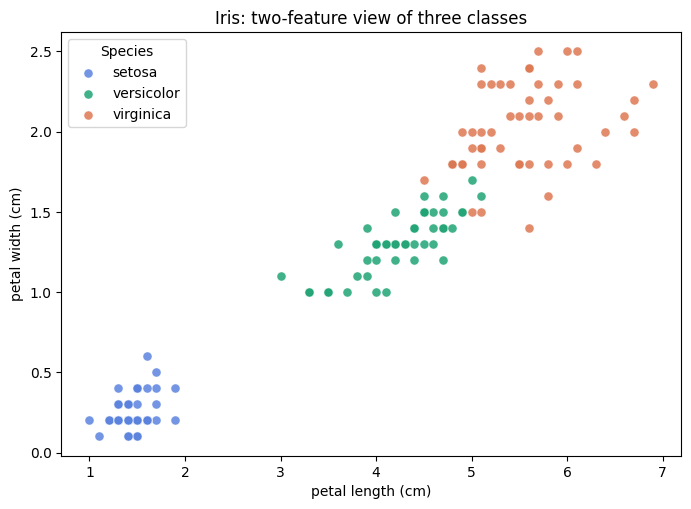

In [29]:
fig, ax = plt.subplots(figsize=(8, 5.5))
palette = ["#5b83de", "#20a475", "#dd7852"]
for class_id, name in enumerate(iris.target_names):
    subset = X[y == class_id]
    ax.scatter(subset.iloc[:, 0], subset.iloc[:, 1], label=name,
               color=palette[class_id], alpha=0.85, s=43, edgecolor="white", linewidth=0.4)
ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title="Iris: two-feature view of three classes")
ax.legend(title="Species")
plt.show()

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts: ", y_test.value_counts().sort_index().to_dict())


Train: 112 rows | Test: 38 rows
Train class counts: {0: 38, 1: 37, 2: 37}
Test class counts:  {0: 12, 1: 13, 2: 13}


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
print(knn_pipeline)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline_cv = cross_validate(
    knn_pipeline,
    X_train, y_train,
    cv = cv,
    scoring="accuracy",
    return_train_score=True,
)
print("Baseline validation accuracy per fold:", np.round(baseline_cv["test_score"], 3))
print(f"Mean validation accuracy: {baseline_cv['test_score'].mean():.3f}")
print(f"Std across folds:        {baseline_cv['test_score'].std():.3f}")
print(f"Mean train accuracy:     {baseline_cv['train_score'].mean():.3f}")

Baseline validation accuracy per fold: [1.    0.913 1.    0.955 1.   ]
Mean validation accuracy: 0.974
Std across folds:        0.035
Mean train accuracy:     0.971


In [33]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "knn__n_neighbors": list(range(1,22,2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

In [34]:
grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv = cv,
    return_train_score=True,
    refit=True,
    n_jobs=1,
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best mean CV accuracy: {grid.best_score_:.3f}")
print("Best estimator:", grid.best_estimator_)

Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform'}
Best mean CV accuracy: 0.974
Best estimator: Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(p=1))])


In [35]:
results = pd.DataFrame(grid.cv_results_)
summary_cols = [
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"
]
best_rows = results.sort_values(["rank_test_score", "std_test_score"]).head(12)
display(best_rows[summary_cols].round(4).reset_index(drop=True))

,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,5,uniform,1,0.9710,0.9735,0.0350,1
1,5,uniform,2,0.9710,0.9735,0.0350,1
2,7,uniform,2,0.9710,0.9735,0.0350,1
3,9,uniform,2,0.9710,0.9735,0.0350,1
4,11,uniform,2,0.9710,0.9735,0.0350,1
5,13,uniform,2,0.9732,0.9735,0.0350,1
6,15,uniform,2,0.9710,0.9735,0.0350,1
7,21,uniform,2,0.9710,0.9735,0.0350,1
8,7,uniform,1,0.9688,0.9648,0.0508,9
9,9,uniform,1,0.9643,0.9648,0.0508,9


Final training accuracy: 0.973
Best mean CV accuracy:   0.974
Held-out test accuracy:  0.947

Classification report (held-out test set):
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        12
  versicolor      0.923     0.923     0.923        13
   virginica      0.923     0.923     0.923        13

    accuracy                          0.947        38
   macro avg      0.949     0.949     0.949        38
weighted avg      0.947     0.947     0.947        38



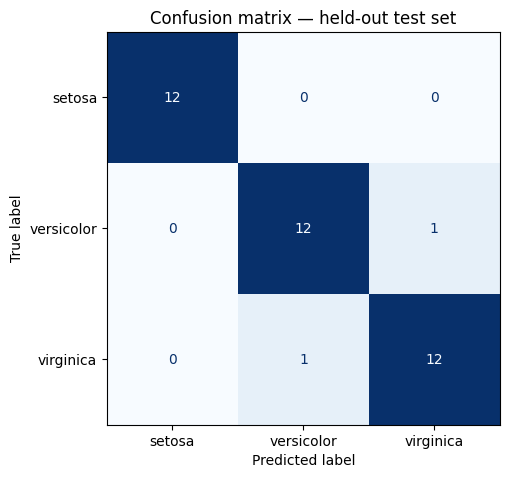

In [36]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
train_accuracy = accuracy_score(y_train, best_model.predict(X_train))
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Final training accuracy: {train_accuracy:.3f}")
print(f"Best mean CV accuracy:   {grid.best_score_:.3f}")
print(f"Held-out test accuracy:  {test_accuracy:.3f}")
print("\nClassification report (held-out test set):")
print(classification_report(y_test, y_pred, target_names=iris.target_names, digits=3))

fig, ax = plt.subplots(figsize=(6.2, 5.1))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Confusion matrix — held-out test set")
plt.show()

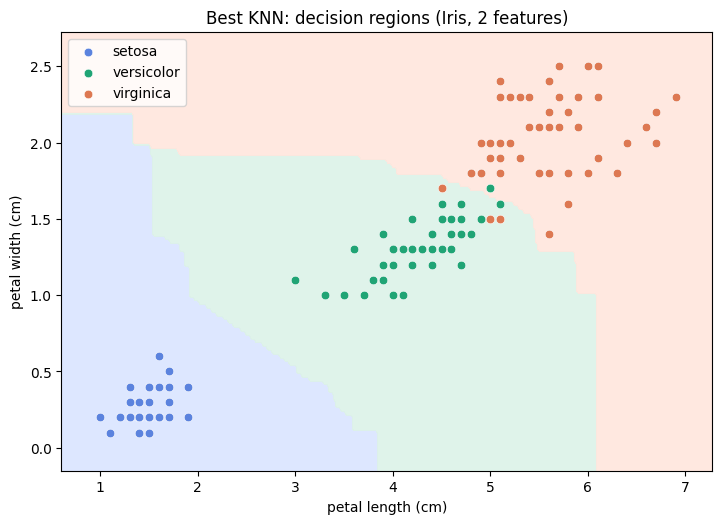

In [37]:
from matplotlib.colors import ListedColormap

step = 0.025
x_min, x_max = X[feature_names[0]].min() - 0.4, X[feature_names[0]].max() + 0.4
y_min, y_max = X[feature_names[1]].min() - 0.25, X[feature_names[1]].max() + 0.25
xx, yy = np.meshgrid(np.arange(x_min, x_max, step), np.arange(y_min, y_max, step))
mesh = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_names)
region = best_model.predict(mesh).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8.4, 5.7))
ax.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5, 2.5],
            cmap=ListedColormap(["#dae5ff", "#dcf2e8", "#ffe6dd"]), alpha=0.9)
for cid, species in enumerate(iris.target_names):
    subset = X[y == cid]
    ax.scatter(subset.iloc[:, 0], subset.iloc[:, 1],
               color=["#5b83de", "#20a475", "#dd7852"][cid],
               s=38, label=species, edgecolor="white", linewidth=0.4)
ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title="Best KNN: decision regions (Iris, 2 features)")
ax.legend()
plt.show()

In [38]:
new_flower = pd.DataFrame([[4.6, 1.4]], columns=feature_names)
predicted_id = int(best_model.predict(new_flower)[0])
probabilities = best_model.predict_proba(new_flower)[0]
print("Predicted species:", iris.target_names[predicted_id])
print("KNN estimated class probabilities:",
      dict(zip(iris.target_names, np.round(probabilities, 3))))

# Access the scaler and KNN inside the fitted pipeline.
scaled_new_flower = best_model.named_steps["scaler"].transform(new_flower)
neighbors_dist, neighbor_idx = best_model.named_steps["knn"].kneighbors(scaled_new_flower)
neighbor_table = X_train.iloc[neighbor_idx[0]].copy()
neighbor_table["species"] = [iris.target_names[int(v)] for v in y_train.iloc[neighbor_idx[0]]]
neighbor_table["scaled_distance"] = neighbors_dist[0]
display(neighbor_table.round(3))

Predicted species: versicolor
KNN estimated class probabilities: {np.str_('setosa'): np.float64(0.0), np.str_('versicolor'): np.float64(1.0), np.str_('virginica'): np.float64(0.0)}


,petal length (cm),petal width (cm),species,scaled_distance
91,4.6,1.4,versicolor,0.000
50,4.7,1.4,versicolor,0.056
65,4.4,1.4,versicolor,0.113
75,4.4,1.4,versicolor,0.113
76,4.8,1.4,versicolor,0.113
